##### Copyright 2018 The TensorFlow Authors.

In [ ]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Extra Lab 01: Text classification with an RNN

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rses-dl-course/rses-dl-course.github.io/blob/master/notebooks/python/XL01_text_classification_rnn.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/rses-dl-course/rses-dl-course.github.io/blob/master/notebooks/python/XL01_text_classification_rnn.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
</table>

This text classification tutorial trains a [recurrent neural network](https://developers.google.com/machine-learning/glossary/#recurrent_neural_network) on the [IMDB large movie review dataset](http://ai.stanford.edu/~amaas/data/sentiment/) for sentiment analysis.

## Setup

In [ ]:
!pip install -q tensorflow_datasets

In [ ]:
import numpy as np

import tensorflow_datasets as tfds
import tensorflow as tf

tfds.disable_progress_bar()

Import `matplotlib` and create a helper function to plot graphs:

In [ ]:
import matplotlib.pyplot as plt

def plot_graphs(history, metric):
  plt.plot(history.history[metric])
  plt.plot(history.history['val_'+metric], '')
  plt.xlabel("Epochs")
  plt.ylabel(metric)
  plt.legend([metric, 'val_'+metric])

## Setup input pipeline


The IMDB large movie review dataset is a *binary classification* dataset—all the reviews have either a *positive* or *negative* sentiment.

Download the dataset using [TFDS](https://www.tensorflow.org/datasets). See the [loading text tutorial](../load_data/text.ipynb) for details on how to load this sort of data manually.


In [ ]:
dataset, info = tfds.load('imdb_reviews', with_info=True,
                          as_supervised=True)
train_dataset, test_dataset = dataset['train'], dataset['test']

train_dataset.element_spec

Initially this returns a dataset of (text, label pairs):

In [ ]:
for example, label in train_dataset.take(1):
  print('text: ', example.numpy())
  print('label: ', label.numpy())

Next shuffle the data for training and create batches of these `(text, label)` pairs:

In [ ]:
BUFFER_SIZE = 10000
BATCH_SIZE = 64

In [ ]:
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
for example, label in train_dataset.take(1):
  print('texts: ', example.numpy()[:3])
  print()
  print('labels: ', label.numpy()[:3])

## Create the text encoder

The raw text loaded by `tfds` needs to be processed before it can be used in a model. The simplest way to process text for training is using the `experimental.preprocessing.TextVectorization` layer. This layer has many capabilities, but this tutorial sticks to the default behavior.

Create the layer, and pass the dataset's text to the layer's `.adapt` method:

In [ ]:
VOCAB_SIZE=1000
encoder = tf.keras.layers.experimental.preprocessing.TextVectorization(
    max_tokens=VOCAB_SIZE)
encoder.adapt(train_dataset.map(lambda text, label: text))

The `.adapt` method sets the layer's vocabulary. Here are the first 20 tokens. After the padding and unknown tokens they're sorted by frequency:

In [ ]:
vocab = np.array(encoder.get_vocabulary())
vocab[:20]

Once the vocabulary is set, the layer can encode text into indices. The tensors of indices are 0-padded to the longest sequence in the batch (unless you set a fixed `output_sequence_length`):

In [ ]:
encoded_example = encoder(example)[:3].numpy()
encoded_example

With the default settings, the process is not completely reversible. There are three main reasons for that:

1. The default value for `preprocessing.TextVectorization`'s `standardize` argument is `"lower_and_strip_punctuation"`.
2. The limited vocabulary size and lack of character-based fallback results in some unknown tokens.

In [ ]:
for n in range(3):
  print("Original: ", example[n].numpy())
  print("Round-trip: ", " ".join(vocab[encoded_example[n]]))
  print()

## Create the model

![A drawing of the information flow in the model](https://github.com/rses-dl-course/rses-dl-course.github.io/blob/master/notebooks/assets/images/bidirectional.png?raw=1)

Above is a diagram of the model.

1. This model can be build as a `tf.keras.Sequential`.

1. The first layer is the `encoder`, which converts the text to a sequence of token indices.

2. After the encoder is an embedding layer. An embedding layer stores one vector per word. When called, it converts the sequences of word indices to sequences of vectors. These vectors are trainable. After training (on enough data), words with similar meanings often have similar vectors.

  This index-lookup is much more efficient than the equivalent operation of passing a one-hot encoded vector through a `tf.keras.layers.Dense` layer.

3. A recurrent neural network (RNN) processes sequence input by iterating through the elements. RNNs pass the outputs from one timestep to their input on the next timestep.

  The `tf.keras.layers.Bidirectional` wrapper can also be used with an RNN layer. This propagates the input forward and backwards through the RNN layer and then concatenates the final output.

  * The main advantage to a bidirectional RNN is that the signal from the beginning of the input doesn't need to be processed all the way through every timestep to affect the output.  

  * The main disadvantage of a bidirectional RNN is that you can't efficiently stream predictions as words are being added to the end.

1. After the RNN has converted the sequence to a single vector the two `layers.Dense` do some final processing, and convert from this vector representation to a single logit as the classification output.


The code to implement this is below:

In [ ]:
model = tf.keras.Sequential([
    encoder,
    tf.keras.layers.Embedding(
        input_dim=len(encoder.get_vocabulary()),
        output_dim=64,
        # Use masking to handle the variable sequence lengths
        mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])

Please note that Keras sequential model is used here since all the layers in the model only have single input and produce single output. In case you want to use stateful RNN layer, you might want to build your model with Keras functional API or model subclassing so that you can retrieve and reuse the RNN layer states. Please check [Keras RNN guide](https://www.tensorflow.org/guide/keras/rnn#rnn_state_reuse) for more details.

The embedding layer [uses masking](../../guide/keras/masking_and_padding) to handle the varying sequence-lengths. All the layers after the `Embedding` support masking:

In [ ]:
print([layer.supports_masking for layer in model.layers])

To confirm that this works as expected, evaluate a sentence twice. First, alone so there's no padding to mask:

In [ ]:
# predict on a sample text without padding.

sample_text = ('The movie was cool. The animation and the graphics '
               'were out of this world. I would recommend this movie.')
predictions = model.predict(np.array([sample_text]))
print(predictions[0])

Now, evaluate it again in a batch with a longer sentence. The result should be identical:

In [ ]:
# predict on a sample text with padding

padding = "the " * 2000
predictions = model.predict(np.array([sample_text, padding]))
print(predictions[0])

Compile the Keras model to configure the training process:

In [ ]:
model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer=tf.keras.optimizers.Adam(1e-4),
              metrics=['accuracy'])

## Train the model

In [ ]:
history = model.fit(train_dataset, epochs=10,
                    validation_data=test_dataset,
                    validation_steps=30)

In [ ]:
test_loss, test_acc = model.evaluate(test_dataset)

print('Test Loss: {}'.format(test_loss))
print('Test Accuracy: {}'.format(test_acc))

In [ ]:
plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plot_graphs(history, 'accuracy')
plt.ylim(None,1)
plt.subplot(1,2,2)
plot_graphs(history, 'loss')
plt.ylim(0,None)

Run a prediction on a new sentence:

If the prediction is >= 0.0, it is positive else it is negative.

In [ ]:
sample_text = ('The movie was cool. The animation and the graphics '
               'were out of this world. I would recommend this movie.')
predictions = model.predict(np.array([sample_text]))

## Stack two or more LSTM layers

Keras recurrent layers have two available modes that are controlled by the `return_sequences` constructor argument:

* If `False` it returns only the last output for each input sequence (a 2D tensor of shape (batch_size, output_features)). This is the default, used in the previous model.

* If `True` the full sequences of successive outputs for each timestep is returned (a 3D tensor of shape `(batch_size, timesteps, output_features)`).

Here is what the flow of information looks like with `return_sequences=True`:

![layered_bidirectional](https://github.com/rses-dl-course/rses-dl-course.github.io/blob/master/notebooks/assets/images/layered_bidirectional.png?raw=1)

The interesting thing about using an `RNN` with `return_sequences=True` is that the output still has 3-axes, like the input, so it can be passed to another RNN layer, like this:

In [ ]:
model = tf.keras.Sequential([
    encoder,
    tf.keras.layers.Embedding(len(encoder.get_vocabulary()), 64, mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64,  return_sequences=True)),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1)
])

In [ ]:
model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer=tf.keras.optimizers.Adam(1e-4),
              metrics=['accuracy'])

In [ ]:
history = model.fit(train_dataset, epochs=10,
                    validation_data=test_dataset,
                    validation_steps=30)

In [ ]:
test_loss, test_acc = model.evaluate(test_dataset)

print('Test Loss: {}'.format(test_loss))
print('Test Accuracy: {}'.format(test_acc))

In [ ]:
# predict on a sample text without padding.

sample_text = ('The movie was not good. The animation and the graphics '
                    'were terrible. I would not recommend this movie.')
predictions = model.predict(np.array([sample_text]))
print(predictions)

In [ ]:
plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
plot_graphs(history, 'accuracy')
plt.subplot(1,2,2)
plot_graphs(history, 'loss')

Check out other existing recurrent layers such as [GRU layers](https://www.tensorflow.org/api_docs/python/tf/keras/layers/GRU).

If you're interested in building custom RNNs, see the [Keras RNN Guide](../../guide/keras/rnn.ipynb).


---
# Extended Task (a): Replacing word-level TextVectorization with other tokenizers

**Why the data is reloaded first.** The pipeline above loads IMDB with `num_words=1000`, so every word outside the 1,000 most frequent ones is already replaced by `<unk>` *before* any tokenizer sees the text. A subword or character tokenizer cannot show its main strength (handling rare and unseen words) on text where those words have already been deleted. For a fair comparison we reload the **full-vocabulary** text and run every tokenizer on exactly the same reviews.

**Second fix.** The original run used the test set as `validation_data`, so the test set influenced training decisions. Here we hold out 20% of the training set for validation and only touch the test set once, at the end.

**What changes and what stays fixed.**

| Kept identical across runs | Changed |
|---|---|
| Embedding(64) → BiLSTM(64) → Dense(64, relu) → Dense(1) | Tokenizer |
| Adam(1e-3), batch 64, max 10 epochs, early stopping on val_loss (patience 2) | Vocabulary size (as a property of each tokenizer) |
| Same train / val / test split, seed 42 | Sequence length (tokens vs characters) |

Tokenizers compared:
1. **Word-level, 1k vocab** (same as the original lab)
2. **Word-level, 8k vocab** (isolates the effect of vocabulary size)
3. **Subword BPE, 8k vocab** (Byte-Pair Encoding trained on the training reviews with Hugging Face `tokenizers`)
4. **Character-level** (`TextVectorization(split='character')`)

Comparing (2) and (3) at the same vocabulary size separates "better tokenizer" from "bigger vocabulary".

In [41]:
import os, json, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)
os.makedirs('results', exist_ok=True)
RESULTS = {}

# Full-vocabulary IMDB (no 1,000-word cap this time)
(imdb_tr_seq, imdb_tr_y), (imdb_te_seq, imdb_te_y) = tf.keras.datasets.imdb.load_data(num_words=None)
imdb_index = tf.keras.datasets.imdb.get_word_index()
imdb_idx2word = {v + 3: k for k, v in imdb_index.items()}   # keras reserves 0-3

def decode_imdb(seq):
    # drop the reserved ids (0 pad, 1 start, 2 oov, 3 unused)
    return " ".join(imdb_idx2word.get(i, "") for i in seq if i > 3)

texts_all = [decode_imdb(s) for s in imdb_tr_seq]
texts_test = [decode_imdb(s) for s in imdb_te_seq]
y_all = np.array(imdb_tr_y, dtype='float32')
y_test = np.array(imdb_te_y, dtype='float32')

texts_tr, texts_val, y_tr, y_val = train_test_split(
    texts_all, y_all, test_size=0.2, random_state=SEED, stratify=y_all)

print(f"train {len(texts_tr)} | val {len(texts_val)} | test {len(texts_test)}")
print("Sample (full vocab):", texts_tr[0][:300])

train 20000 | val 5000 | test 25000
Sample (full vocab): sorry to say i have no idea what hollywood is doing sure give us movies like batman begins oh by the way hollywood i think they may cover the story line in the movie batman but please don't entertain us what we would really want to see batman and superman together i really hated this trailer because


### Build the four tokenizers

Every tokenizer is fitted on the **training split only** and outputs fixed-length, right-padded integer arrays with `0` as the padding id, so the same `mask_zero=True` model works for all of them. Reviews are truncated to 300 tokens (word / subword) or 1,200 characters (character-level, roughly the same amount of text) to keep training time reasonable.

In [42]:
MAX_LEN_TOK = 300     # word and subword tokens per review
MAX_LEN_CHAR = 1200   # characters per review (~ same amount of text)

def tv_to_array(layer, texts, batch=2000):
    parts = [layer(tf.constant(texts[i:i + batch])).numpy() for i in range(0, len(texts), batch)]
    return np.concatenate(parts).astype('int32')

def unk_rate(arr, unk_id=1):
    nonpad = arr[arr != 0]
    return float((nonpad == unk_id).mean())

TOKENIZED = {}

# 1 & 2) Word-level TextVectorization (the original tokenizer) at two vocab sizes
for vocab in (1000, 8000):
    tv = tf.keras.layers.TextVectorization(max_tokens=vocab, output_sequence_length=MAX_LEN_TOK)
    tv.adapt(tf.data.Dataset.from_tensor_slices(texts_tr).batch(1024))
    name = f"Word ({vocab // 1000}k vocab)"
    TOKENIZED[name] = dict(
        train=tv_to_array(tv, texts_tr), val=tv_to_array(tv, texts_val), test=tv_to_array(tv, texts_test),
        vocab_size=len(tv.get_vocabulary()), max_len=MAX_LEN_TOK,
        example=" | ".join(tv.get_vocabulary()[i] for i in tv(tf.constant([texts_tr[0]])).numpy()[0][:15]))

# 3) Subword BPE (Hugging Face `tokenizers`, preinstalled on Colab)
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers
bpe = Tokenizer(models.BPE(unk_token="[UNK]"))
bpe.normalizer = normalizers.Lowercase()
bpe.pre_tokenizer = pre_tokenizers.Whitespace()
bpe.train_from_iterator(texts_tr, trainer=trainers.BpeTrainer(
    vocab_size=8000, special_tokens=["[PAD]", "[UNK]"]))
assert bpe.token_to_id("[PAD]") == 0 and bpe.token_to_id("[UNK]") == 1

# token-length statistics before truncation
bpe_lengths = [len(e.ids) for e in bpe.encode_batch(texts_test[:2000])]
bpe_example = " | ".join(bpe.encode(texts_tr[0]).tokens[:15])

bpe.enable_padding(pad_id=0, pad_token="[PAD]", length=MAX_LEN_TOK)
bpe.enable_truncation(max_length=MAX_LEN_TOK)
def bpe_to_array(texts):
    return np.array([e.ids for e in bpe.encode_batch(texts)], dtype='int32')

TOKENIZED["Subword BPE (8k vocab)"] = dict(
    train=bpe_to_array(texts_tr), val=bpe_to_array(texts_val), test=bpe_to_array(texts_test),
    vocab_size=bpe.get_vocab_size(), max_len=MAX_LEN_TOK, example=bpe_example)

# 4) Character-level TextVectorization
char_tv = tf.keras.layers.TextVectorization(
    split='character', standardize='lower', output_sequence_length=MAX_LEN_CHAR)
char_tv.adapt(tf.data.Dataset.from_tensor_slices(texts_tr).batch(1024))
char_vocab = char_tv.get_vocabulary()
TOKENIZED["Character"] = dict(
    train=tv_to_array(char_tv, texts_tr), val=tv_to_array(char_tv, texts_val), test=tv_to_array(char_tv, texts_test),
    vocab_size=len(char_vocab), max_len=MAX_LEN_CHAR,
    example=" | ".join(char_vocab[i] for i in char_tv(tf.constant([texts_tr[0]])).numpy()[0][:15]))

# Statistics for the slides
word_lengths = [len(t.split()) for t in texts_test[:2000]]
char_lengths = [len(t) for t in texts_test[:2000]]
raw_len = {"Word (1k vocab)": word_lengths, "Word (8k vocab)": word_lengths,
           "Subword BPE (8k vocab)": bpe_lengths, "Character": char_lengths}

tok_stats = []
for name, d in TOKENIZED.items():
    L = np.array(raw_len[name])
    tok_stats.append(dict(
        tokenizer=name, vocab_size=d['vocab_size'], max_len=d['max_len'],
        mean_tokens_per_review=round(float(L.mean()), 1),
        pct_reviews_truncated=round(100 * float((L > d['max_len']).mean()), 1),
        pct_unknown_tokens=round(100 * unk_rate(d['test']), 2),
        first_15_tokens=d['example']))
tok_stats_df = pd.DataFrame(tok_stats).set_index('tokenizer')
RESULTS['tokenizer_stats'] = tok_stats
tok_stats_df

,vocab_size,max_len,mean_tokens_per_review,pct_reviews_truncated,pct_unknown_tokens,first_15_tokens
tokenizer,,,,,,
Word (1k vocab),1000,300,228.3,21.1,22.29,sorry | to | say | i | have | no | idea | what...
Word (8k vocab),8000,300,228.3,21.1,5.97,sorry | to | say | i | have | no | idea | what...
Subword BPE (8k vocab),8000,300,263.3,27.1,0.00,sorry | to | say | i | have | no | idea | what...
Character,121,1200,1221.5,34.1,0.00,s | o | r | r | y | | t | o | | s | a | y ...


### Train the same BiLSTM on each tokenizer's output

The model is the original lab's single-layer BiLSTM. The only difference is that the `encoder` layer is removed from the model, because each tokenizer now runs beforehand and the model receives integer ids directly.

In [43]:
def build_bilstm(vocab_size, n_outputs=1, emb_dim=64, dropout=0.0):
    layers = [
        tf.keras.Input(shape=(None,), dtype='int32'),
        tf.keras.layers.Embedding(vocab_size, emb_dim, mask_zero=True),
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
        tf.keras.layers.Dense(64, activation='relu'),
    ]
    if dropout:
        layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(n_outputs))   # logits
    return tf.keras.Sequential(layers)

EPOCHS_A = 10
task_a_rows, task_a_hist = [], {}

for name, d in TOKENIZED.items():
    print(f"\n===== {name} =====")
    tf.keras.utils.set_random_seed(SEED)
    model = build_bilstm(d['vocab_size'])
    model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
                  optimizer=tf.keras.optimizers.Adam(1e-3),
                  metrics=['accuracy'])
    early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(d['train'], y_tr, validation_data=(d['val'], y_val),
                     epochs=EPOCHS_A, batch_size=64, callbacks=[early], verbose=2)
    train_time = time.time() - t0
    test_loss, test_acc = model.evaluate(d['test'], y_test, batch_size=256, verbose=0)
    n_ep = len(hist.history['loss'])
    task_a_rows.append(dict(
        tokenizer=name, test_accuracy=round(float(test_acc), 4), test_loss=round(float(test_loss), 4),
        best_val_accuracy=round(float(max(hist.history['val_accuracy'])), 4),
        epochs_run=n_ep, sec_per_epoch=round(train_time / n_ep, 1),
        params=int(model.count_params())))
    task_a_hist[name] = {k: [float(x) for x in v] for k, v in hist.history.items()}
    print(f"Test accuracy: {test_acc:.4f}")

task_a_df = pd.DataFrame(task_a_rows).set_index('tokenizer')
RESULTS['task_a'] = task_a_rows
RESULTS['task_a_history'] = task_a_hist
task_a_df


===== Word (1k vocab) =====
Epoch 1/10
313/313 - 16s - 50ms/step - accuracy: 0.6733 - loss: 0.5472 - val_accuracy: 0.7708 - val_loss: 0.4450
Epoch 2/10
313/313 - 18s - 57ms/step - accuracy: 0.8416 - loss: 0.3553 - val_accuracy: 0.8178 - val_loss: 0.3709
Epoch 3/10
313/313 - 14s - 45ms/step - accuracy: 0.8594 - loss: 0.3204 - val_accuracy: 0.7594 - val_loss: 0.4457
Epoch 4/10
313/313 - 10s - 31ms/step - accuracy: 0.8681 - loss: 0.3010 - val_accuracy: 0.7798 - val_loss: 0.4252
Test accuracy: 0.8293

===== Word (8k vocab) =====
Epoch 1/10
313/313 - 12s - 38ms/step - accuracy: 0.7671 - loss: 0.4358 - val_accuracy: 0.8478 - val_loss: 0.3260
Epoch 2/10
313/313 - 12s - 38ms/step - accuracy: 0.9068 - loss: 0.2321 - val_accuracy: 0.8570 - val_loss: 0.3684
Epoch 3/10
313/313 - 18s - 57ms/step - accuracy: 0.9297 - loss: 0.1776 - val_accuracy: 0.8558 - val_loss: 0.3734
Test accuracy: 0.8380

===== Subword BPE (8k vocab) =====
Epoch 1/10
313/313 - 11s - 36ms/step - accuracy: 0.7778 - loss: 0.4293 

,test_accuracy,test_loss,best_val_accuracy,epochs_run,sec_per_epoch,params
tokenizer,,,,,,
Word (1k vocab),0.8293,0.3509,0.8178,4,14.3,138369
Word (8k vocab),0.8380,0.3375,0.8570,3,13.8,586369
Subword BPE (8k vocab),0.8196,0.3566,0.8540,3,9.7,586369
Character,0.5367,0.6689,0.5372,6,28.8,82113


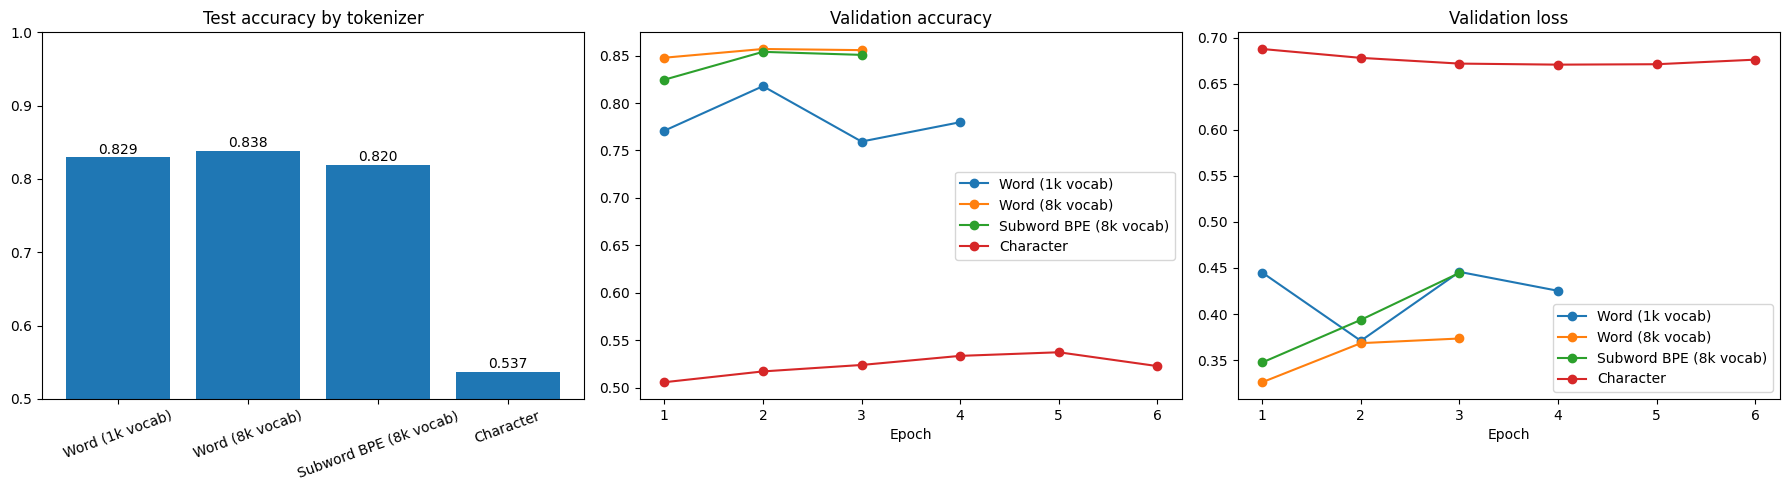

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

names = list(task_a_df.index)
axes[0].bar(names, task_a_df['test_accuracy'])
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title('Test accuracy by tokenizer')
axes[0].tick_params(axis='x', rotation=20)
for i, v in enumerate(task_a_df['test_accuracy']):
    axes[0].text(i, v + 0.005, f"{v:.3f}", ha='center')

for name, h in task_a_hist.items():
    axes[1].plot(range(1, len(h['val_accuracy']) + 1), h['val_accuracy'], marker='o', label=name)
    axes[2].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], marker='o', label=name)
axes[1].set_title('Validation accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
axes[2].set_title('Validation loss'); axes[2].set_xlabel('Epoch'); axes[2].legend()
plt.tight_layout()
plt.savefig('results/task_a_tokenizers.png', dpi=150)
plt.show()

---
# Extended Task (b): Switching to a multiclass dataset (Reuters newswire, 46 topics)

**Dataset choice.** Reuters-21578 ships with Keras (`tf.keras.datasets.reuters`), loads from the same reliable mirror as IMDB, and has **46 topic classes** (8,982 training and 2,246 test articles). It is heavily imbalanced: a couple of classes (`earn`, `acq`) cover most articles, so accuracy alone is misleading. We therefore also report **macro-F1** and a **majority-class baseline**.

**What has to change for multiclass, layer by layer:**

| Part of the model | Binary (IMDB) | Multiclass (Reuters) | Why |
|---|---|---|---|
| Text encoder | TextVectorization, 1k vocab | TextVectorization, 10k vocab | News vocabulary is more specific; topic words are often rare |
| Embedding / BiLSTM | unchanged | unchanged | Sequence encoding is task-independent |
| Hidden Dense | Dense(64, relu) | Dense(64, relu) + **Dropout(0.3)** | Only ~7.6k training articles, so overfitting is the main risk |
| **Output layer** | `Dense(1)` (one logit) | **`Dense(46)`** (one logit per class) | One score per topic |
| **Loss** | `BinaryCrossentropy(from_logits=True)` | **`SparseCategoricalCrossentropy(from_logits=True)`** | Labels are integers 0–45, softmax over classes |
| **Prediction** | logit ≥ 0 → positive | **`argmax`** over the 46 logits (softmax for probabilities) | |
| Metrics | accuracy | accuracy + macro-F1 + majority baseline | Imbalance |

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Classes: 46 | train 7634 | val 1348 | test 2246
Largest classes: [('earn', 3159), ('acq', 1949), ('money-fx', 549), ('crude', 444), ('grain', 432)]
Smallest class size: 10

Sample: shr loss 19 cts vs profit 11 cts net loss 1 140 270 vs profit 590 463 revs 1 259 164 vs 3 225 512 year shr loss 67 cts vs profit 10 cts net loss 4 004 840 vs profit 580 488 revs 3 184 480 vs 9 123 041 reuter 3 -> earn


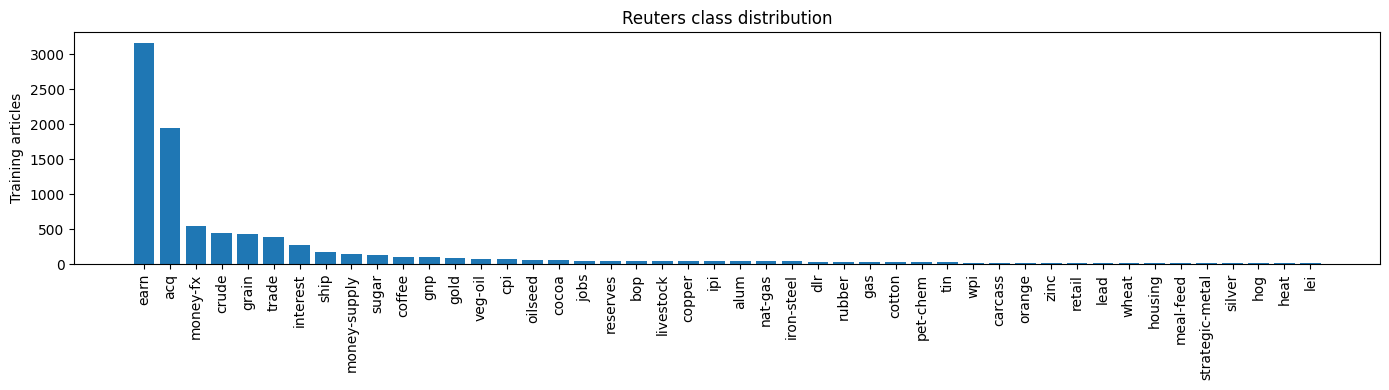

In [45]:
(r_tr_seq, r_tr_y), (r_te_seq, r_te_y) = tf.keras.datasets.reuters.load_data(num_words=None)
r_index = tf.keras.datasets.reuters.get_word_index()
r_idx2word = {v + 3: k for k, v in r_index.items()}

def decode_reuters(seq):
    return " ".join(r_idx2word.get(i, "") for i in seq if i > 3)

r_texts_all = [decode_reuters(s) for s in r_tr_seq]
r_texts_test = [decode_reuters(s) for s in r_te_seq]
r_y_all = np.array(r_tr_y, dtype='int32')
r_y_test = np.array(r_te_y, dtype='int32')

try:
    LABEL_NAMES = list(tf.keras.datasets.reuters.get_label_names())
except Exception:
    LABEL_NAMES = [str(i) for i in range(46)]
NUM_CLASSES = int(max(r_y_all.max(), r_y_test.max()) + 1)

# Not stratified: some topics have only a handful of training articles
r_tr_texts, r_val_texts, r_y_tr, r_y_val = train_test_split(
    r_texts_all, r_y_all, test_size=0.15, random_state=SEED)

counts = pd.Series(r_y_all).value_counts()
print(f"Classes: {NUM_CLASSES} | train {len(r_tr_texts)} | val {len(r_val_texts)} | test {len(r_texts_test)}")
print("Largest classes:", [(LABEL_NAMES[i], int(c)) for i, c in counts.head(5).items()])
print("Smallest class size:", int(counts.min()))
print("\nSample:", r_tr_texts[0][:300], "->", LABEL_NAMES[r_y_tr[0]])

plt.figure(figsize=(14, 4))
plt.bar([LABEL_NAMES[i] for i in counts.index], counts.values)
plt.xticks(rotation=90); plt.ylabel('Training articles'); plt.title('Reuters class distribution')
plt.tight_layout(); plt.savefig('results/task_b_class_distribution.png', dpi=150); plt.show()

RESULTS['task_b_class_counts'] = {LABEL_NAMES[i]: int(c) for i, c in counts.items()}

In [46]:
R_VOCAB, R_MAX_LEN = 10000, 200

r_encoder = tf.keras.layers.TextVectorization(max_tokens=R_VOCAB, output_sequence_length=R_MAX_LEN)
r_encoder.adapt(tf.data.Dataset.from_tensor_slices(r_tr_texts).batch(1024))
Xr_tr, Xr_val, Xr_te = (tv_to_array(r_encoder, t) for t in (r_tr_texts, r_val_texts, r_texts_test))

tf.keras.utils.set_random_seed(SEED)
r_model = build_bilstm(len(r_encoder.get_vocabulary()), n_outputs=NUM_CLASSES, dropout=0.3)
r_model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                optimizer=tf.keras.optimizers.Adam(1e-3),
                metrics=['accuracy'])
r_model.summary()

t0 = time.time()
r_hist = r_model.fit(Xr_tr, r_y_tr, validation_data=(Xr_val, r_y_val),
                     epochs=30, batch_size=64, verbose=2,
                     callbacks=[tf.keras.callbacks.EarlyStopping(
                         monitor='val_loss', patience=3, restore_best_weights=True)])
r_train_time = time.time() - t0

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, None, 64)       │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 46)             │         2,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 717,294 (2.74 MB)

 Trainable params: 717,294 (2.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
120/120 - 5s - 45ms/step - accuracy: 0.4581 - loss: 2.2811 - val_accuracy: 0.5734 - val_loss: 1.6330
Epoch 2/30
120/120 - 2s - 21ms/step - accuracy: 0.5786 - loss: 1.6176 - val_accuracy: 0.6358 - val_loss: 1.4289
Epoch 3/30
120/120 - 3s - 28ms/step - accuracy: 0.6382 - loss: 1.3933 - val_accuracy: 0.6840 - val_loss: 1.2879
Epoch 4/30
120/120 - 4s - 36ms/step - accuracy: 0.6864 - loss: 1.2033 - val_accuracy: 0.6869 - val_loss: 1.2347
Epoch 5/30
120/120 - 2s - 20ms/step - accuracy: 0.7228 - loss: 1.0569 - val_accuracy: 0.7181 - val_loss: 1.1769
Epoch 6/30
120/120 - 3s - 21ms/step - accuracy: 0.7666 - loss: 0.9020 - val_accuracy: 0.7455 - val_loss: 1.1008
Epoch 7/30
120/120 - 3s - 27ms/step - accuracy: 0.8008 - loss: 0.7711 - val_accuracy: 0.7144 - val_loss: 1.2294
Epoch 8/30
120/120 - 4s - 36ms/step - accuracy: 0.8254 - loss: 0.6814 - val_accuracy: 0.7441 - val_loss: 1.1493
Epoch 9/30
120/120 - 2s - 20ms/step - accuracy: 0.8423 - loss: 0.5969 - val_accuracy: 0.7366 - val_loss:

In [47]:
from sklearn.metrics import f1_score, classification_report, confusion_matrix

r_logits = r_model.predict(Xr_te, batch_size=256, verbose=0)
r_pred = r_logits.argmax(axis=1)

r_test_loss, r_test_acc = r_model.evaluate(Xr_te, r_y_test, verbose=0)
majority_class = int(pd.Series(r_y_tr).mode()[0])
majority_acc = float((r_y_test == majority_class).mean())
macro_f1 = f1_score(r_y_test, r_pred, average='macro', zero_division=0)
weighted_f1 = f1_score(r_y_test, r_pred, average='weighted', zero_division=0)
top3_acc = float(np.mean([y in np.argsort(l)[-3:] for y, l in zip(r_y_test, r_logits)]))

n_ep = len(r_hist.history['loss'])
RESULTS['task_b'] = dict(
    dataset='Reuters newswire', num_classes=NUM_CLASSES,
    n_train=len(r_tr_texts), n_val=len(r_val_texts), n_test=len(r_texts_test),
    test_accuracy=round(float(r_test_acc), 4), top3_accuracy=round(top3_acc, 4),
    macro_f1=round(float(macro_f1), 4), weighted_f1=round(float(weighted_f1), 4),
    majority_baseline_accuracy=round(majority_acc, 4), majority_class=LABEL_NAMES[majority_class],
    epochs_run=n_ep, sec_per_epoch=round(r_train_time / n_ep, 1), params=int(r_model.count_params()),
    classes_never_predicted=int(NUM_CLASSES - len(np.unique(r_pred))))
RESULTS['task_b_history'] = {k: [float(x) for x in v] for k, v in r_hist.history.items()}

for k, v in RESULTS['task_b'].items():
    print(f"{k:28s} {v}")

# Per-class results for the 10 most frequent classes
top10 = counts.index[:10].tolist()
report = classification_report(r_y_test, r_pred, labels=top10,
                               target_names=[LABEL_NAMES[i] for i in top10],
                               zero_division=0, output_dict=True)
RESULTS['task_b_per_class'] = {k: {m: round(float(x), 3) for m, x in v.items()}
                               for k, v in report.items() if k in [LABEL_NAMES[i] for i in top10]}
print(classification_report(r_y_test, r_pred, labels=top10,
                            target_names=[LABEL_NAMES[i] for i in top10], zero_division=0))

dataset                      Reuters newswire
num_classes                  46
n_train                      7634
n_val                        1348
n_test                       2246
test_accuracy                0.7128
top3_accuracy                0.8304
macro_f1                     0.183
weighted_f1                  0.6847
majority_baseline_accuracy   0.362
majority_class               earn
epochs_run                   9
sec_per_epoch                3.4
params                       717294
classes_never_predicted      26
              precision    recall  f1-score   support

        earn       0.93      0.93      0.93       813
         acq       0.85      0.85      0.85       474
    money-fx       0.56      0.71      0.63       133
       crude       0.54      0.74      0.62        99
       grain       0.62      0.67      0.65       105
       trade       0.52      0.76      0.62        83
    interest       0.38      0.21      0.28        70
        ship       0.14      0.16      0.15

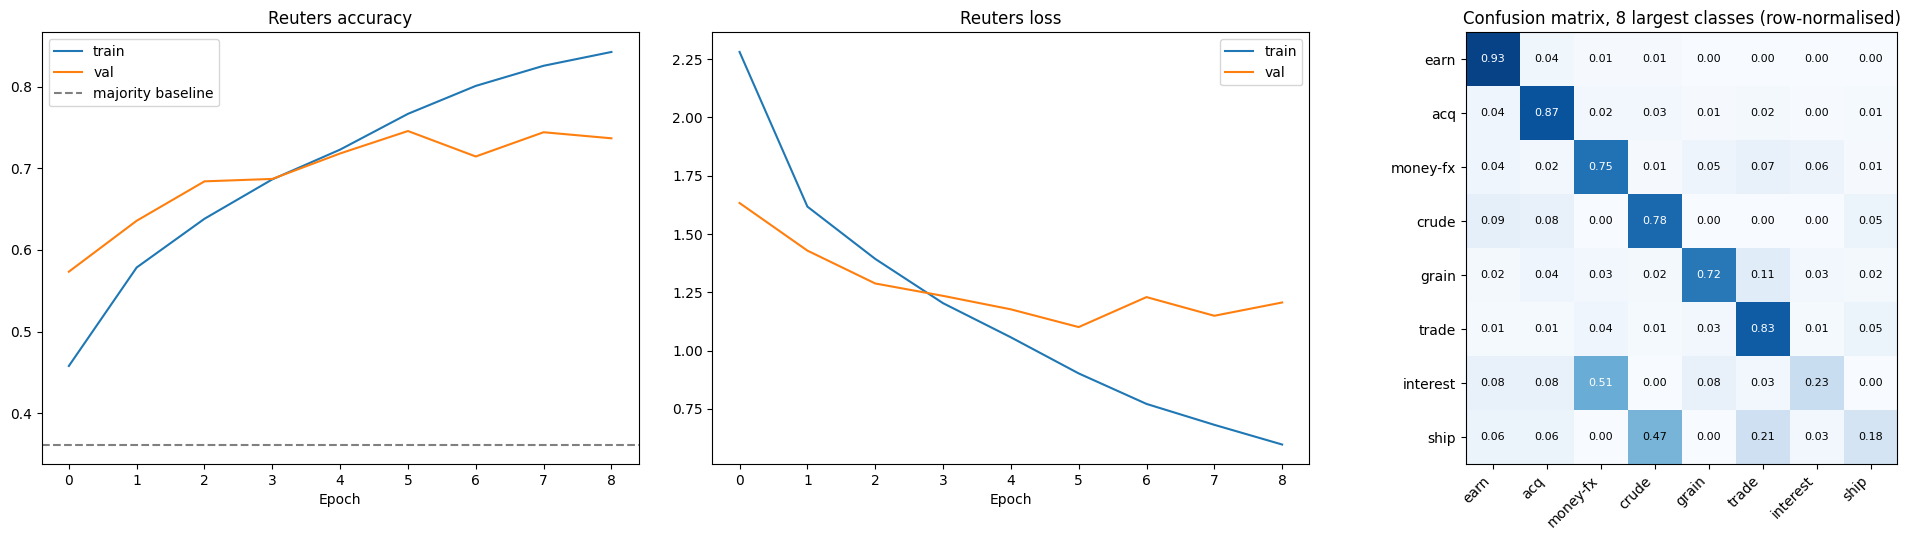

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
h = r_hist.history
axes[0].plot(h['accuracy'], label='train'); axes[0].plot(h['val_accuracy'], label='val')
axes[0].axhline(majority_acc, ls='--', c='grey', label='majority baseline')
axes[0].set_title('Reuters accuracy'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(h['loss'], label='train'); axes[1].plot(h['val_loss'], label='val')
axes[1].set_title('Reuters loss'); axes[1].set_xlabel('Epoch'); axes[1].legend()

top8 = counts.index[:8].tolist()
mask = np.isin(r_y_test, top8)
cm = confusion_matrix(r_y_test[mask], r_pred[mask], labels=top8, normalize='true')
im = axes[2].imshow(cm, cmap='Blues', vmin=0, vmax=1)
axes[2].set_xticks(range(8)); axes[2].set_yticks(range(8))
axes[2].set_xticklabels([LABEL_NAMES[i] for i in top8], rotation=45, ha='right')
axes[2].set_yticklabels([LABEL_NAMES[i] for i in top8])
axes[2].set_title('Confusion matrix, 8 largest classes (row-normalised)')
for i in range(8):
    for j in range(8):
        axes[2].text(j, i, f"{cm[i, j]:.2f}", ha='center', va='center',
                     color='white' if cm[i, j] > 0.5 else 'black', fontsize=8)
plt.tight_layout(); plt.savefig('results/task_b_reuters.png', dpi=150); plt.show()
RESULTS['task_b_confusion_top8'] = dict(labels=[LABEL_NAMES[i] for i in top8], matrix=cm.round(3).tolist())

In [49]:
# Multiclass prediction: softmax over the 46 logits, report the top 3 topics
def predict_topic(text, k=3):
    ids = tv_to_array(r_encoder, [text])
    probs = tf.nn.softmax(r_model.predict(ids, verbose=0)[0]).numpy()
    return [(LABEL_NAMES[i], round(float(probs[i]), 3)) for i in probs.argsort()[::-1][:k]]

samples = [
    "the company reported first quarter net profit rose to 12 mln dlrs or 45 cts a share",
    "crude oil prices rose after opec agreed to cut production by one mln barrels per day",
    "the central bank raised its discount rate to curb inflation and support the currency",
]
RESULTS['task_b_samples'] = []
for s in samples:
    p = predict_topic(s)
    RESULTS['task_b_samples'].append(dict(text=s, top3=p))
    print(s, "\n   ->", p, "\n")

the company reported first quarter net profit rose to 12 mln dlrs or 45 cts a share 
   -> [('earn', 0.738), ('interest', 0.035), ('money-fx', 0.024)] 

crude oil prices rose after opec agreed to cut production by one mln barrels per day 
   -> [('crude', 0.801), ('ship', 0.142), ('money-supply', 0.009)] 

the central bank raised its discount rate to curb inflation and support the currency 
   -> [('money-supply', 0.204), ('gnp', 0.187), ('sugar', 0.154)] 



---
# Conclusions

## Task (a): Tokenizer comparison (IMDB, full vocabulary, same BiLSTM)

| Tokenizer | Vocab size | Unknown tokens | Test accuracy |
|---|---|---|---|
| Word-level (1k) | 1,000 | 22.3% | 82.9% |
| Word-level (8k) | 8,000 | 6.0% | **83.8%** |
| Subword BPE (8k) | 8,000 | 0.0% | 82.0% |
| Character-level | 121 | 0.0% | 53.7% |

**Word-level with an 8k vocabulary performed best.** Raising the vocabulary from 1k to 8k cut unknown tokens from 22% to 6% and added about 0.9 points, so vocabulary coverage matters.

**BPE removed unknown tokens completely but did not beat word-level at the same vocabulary size** (82.0% vs 83.8% on test, 85.4% vs 85.7% best validation accuracy). The Keras IMDB text is already lowercased with punctuation stripped, and with 8k words only 6% of tokens were unknown, so subwords had little left to recover. BPE also made reviews about 15% longer, so more of them were cut off at 300 tokens (27% vs 21%).

**The character-level model failed to learn** (53.7%, close to the 50% chance level). A single LSTM struggles to carry sentiment across 1,200 time steps, and character models usually need convolutional layers or much longer training. This shows our setup does not suit characters, not that character tokenization cannot work.

**Caveats.** With a learning rate of 1e-3, the word (8k) and BPE models reached their lowest validation loss after epoch 1, so early stopping restored first-epoch weights. Each configuration was run once with one seed, so gaps of 1 to 2 points are not a reliable ranking. All runs score below the original lab's 87.2% because that run used a slower learning rate (1e-4) for 10 epochs and validated on the test set, so the numbers are not directly comparable.

## Task (b): Multiclass classification (Reuters, 46 topics)

Changes from the binary model: output layer `Dense(1)` became `Dense(46)`, loss `BinaryCrossentropy` became `SparseCategoricalCrossentropy`, prediction changed from a threshold at 0 to `argmax`, vocabulary increased to 10k, and `Dropout(0.3)` was added.

| Metric | Value |
|---|---|
| Test accuracy | 71.3% |
| Majority-class baseline (always "earn") | 36.2% |
| Top-3 accuracy | 83.0% |
| Weighted F1 | 0.68 |
| Macro F1 | 0.18 |
| Classes never predicted | 26 of 46 |

The model roughly doubles the majority baseline and is strong on the large classes (F1 of 0.93 for earn and 0.85 for acq). **Macro F1 of 0.18 exposes the weakness:** 26 of the 46 topics were never predicted, because many classes have only 10 to 50 training articles. Accuracy alone hides this. The model also overfit early: validation loss was lowest at epoch 6 and rose afterwards, while training accuracy kept climbing (84% train vs 74% validation by epoch 9).

**Possible improvements:** class weights or oversampling for rare topics, merging very small classes, and pretrained word embeddings such as GloVe.